In [11]:
# Necessary imports #

# System #
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

# General #

import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
import euclidlib as el
import seaborn as sns

# Gaussian processes #

from binz.gp import normalize_dndz, resample_dndz, compute_cdf_nodes, reconstruct_all_bins, resample_dndz_gp
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C, RBF

# Plotting # 

import matplotlib as mpl 
mpl.rcParams['font.family'] = "serif"
mpl.rcParams['font.serif'] = "Times New Roman"
mpl.rcParams['text.usetex'] = True




### Preparing and plotting the original mock $n(z)$

In [12]:
# Import and prepare original n(z) distribution #

zs = np.linspace(1e-4, 3, 100)
z_nz, nz_heracles = el.phz.redshift_distributions('/home/jipdebuck/nz_example.fits')

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz_heracles, z_nz)
dndz_she_norm = normalize_dndz(nz_heracles, z_nz)

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z_nz, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z_nz, zs)

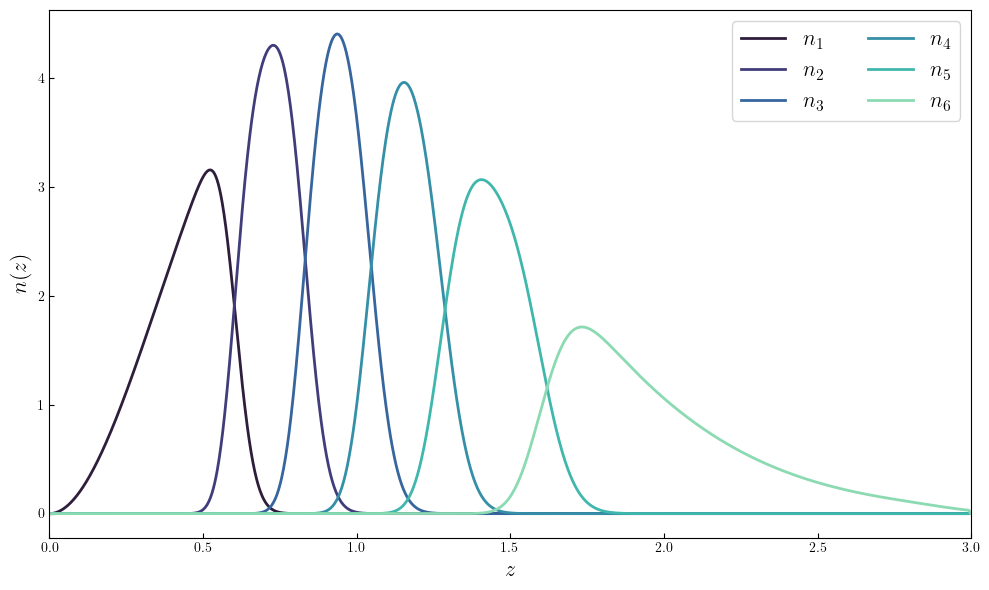

In [13]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(figsize=(10, 6))

# Customize tick parameters for both axes
axs.tick_params(axis='both', which='both', direction='in')

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs.plot(z_nz, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

axs.set_xlabel(r'$z$', fontsize=16)
axs.set_ylabel(r'$n(z)$', fontsize=16)
axs.set_xlim(0, 3)
axs.legend(frameon=True, ncol=2, fontsize=16)

plt.tight_layout()
plt.savefig('/home/jipdebuck/plots/nz_DR3.png', dpi=600, bbox_inches='tight')


### Reconstruct $n(z)$ with GPs using 3 training nodes

In [14]:
# Define GP params # 

z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = RBF
corr_len = 0.065
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

In [15]:
# Perform GP reconstruction with 3 nodes #

x_nodes_all, y_nodes_all = compute_cdf_nodes(z_nz, dndz_she_norm, 3) # compute training node positions 
gp_predictions = reconstruct_all_bins(z_pred, x_nodes_all, y_nodes_all, z_bounds, corr_len, amp=0.04, alpha=alpha,
 kernel_class=kernel_class, nu=nu) # construct GP predictions in all bins
gp_predictions_norm = resample_dndz_gp(gp_predictions, z_pred, zs) # normalize and resample GP predictions

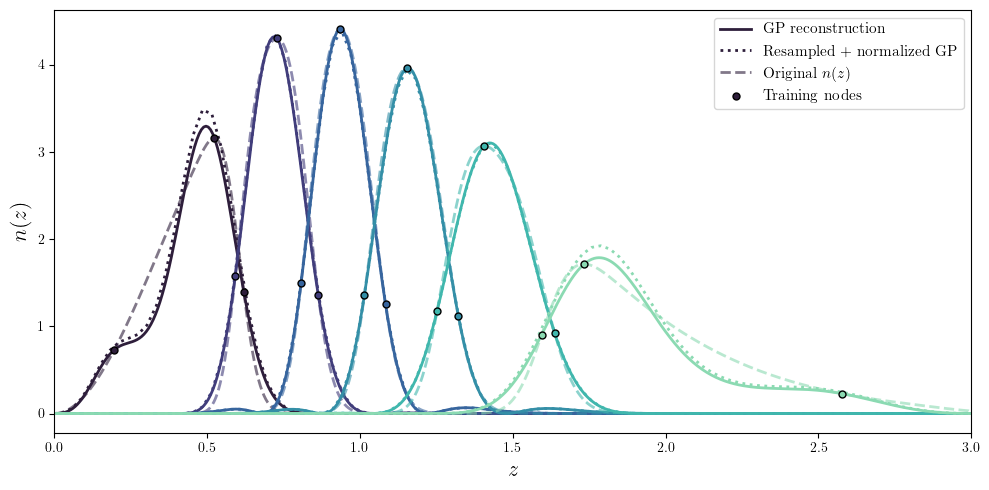

In [16]:
# Plotting #

palette = sns.color_palette("mako", 6)
fig, ax = plt.subplots(figsize=(10, 5))
for j in range(len(dndz_she_norm)):
    bin_id = j + 1
    if j == 0:
        ax.plot(z_pred, gp_predictions[bin_id], color=palette[j], lw=2, label="GP reconstruction")
        ax.plot(zs, gp_predictions_norm[j], color=palette[j], ls=":", lw=2, label="Resampled + normalized GP")
        ax.plot(z_nz, dndz_she_norm[bin_id], "--", color=palette[j], alpha=0.6, lw=2, label="Original $n(z)$")
        ax.scatter(x_nodes_all[j], y_nodes_all[j], color=palette[j], s=25, edgecolor="black", zorder=3, label="Training nodes")
    else:
        ax.plot(z_pred, gp_predictions[bin_id], color=palette[j], lw=2)
        ax.plot(zs, gp_predictions_norm[j], color=palette[j], ls=":", lw=2)
        ax.plot(z_nz, dndz_she_norm[bin_id], "--", color=palette[j], alpha=0.6, lw=2)
        ax.scatter(x_nodes_all[j], y_nodes_all[j], color=palette[j], s=25, edgecolor="black", zorder=3)
ax.set_xlabel(r"$z$", fontsize=16)
ax.set_ylabel(r"$n(z)$", fontsize=16)
ax.set_xlim(0, 3)
ax.legend(fontsize=11)
plt.tight_layout()

### Reconstruct $n(z)$ with GPs using 5 training nodes 

In [17]:
# Perform GP reconstruction with 5 nodes #

corr_len_5 = 0.045

x_nodes_all_5, y_nodes_all_5 = compute_cdf_nodes(z_nz, dndz_she_norm, 5) # compute training node positions 
gp_predictions_5 = reconstruct_all_bins(z_pred, x_nodes_all_5, y_nodes_all_5, z_bounds, corr_len_5, amp=0.04, alpha=alpha,
 kernel_class=kernel_class, nu=nu) # construct GP predictions in all bins
gp_predictions_norm_5 = resample_dndz_gp(gp_predictions_5, z_pred, zs) # normalize and resample GP predictions

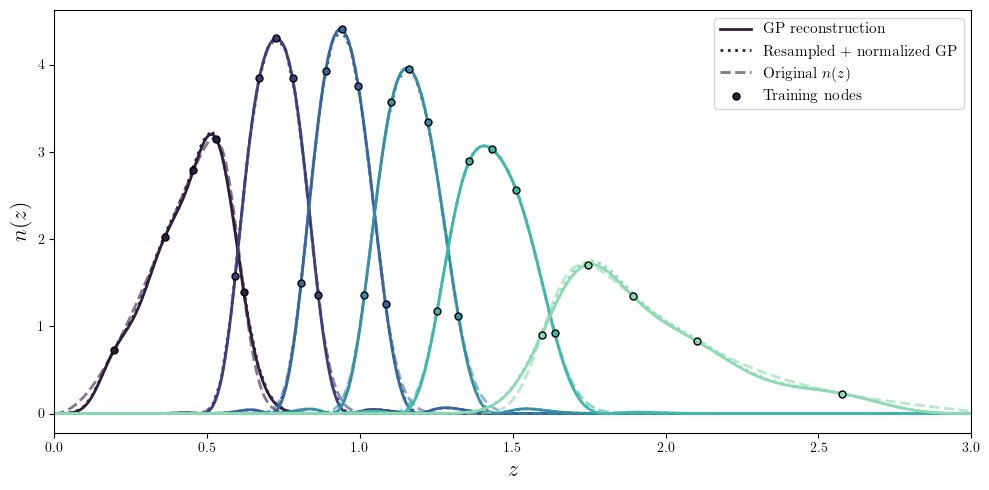

In [18]:
# Plotting #

palette = sns.color_palette("mako", 6)
fig, ax = plt.subplots(figsize=(10, 5))
for j in range(len(dndz_she_norm)):
    bin_id = j + 1
    if j == 0:
        ax.plot(z_pred, gp_predictions_5[bin_id], color=palette[j], lw=2, label="GP reconstruction")
        ax.plot(zs, gp_predictions_norm_5[j], color=palette[j], ls=":", lw=2, label="Resampled + normalized GP")
        ax.plot(z_nz, dndz_she_norm[bin_id], "--", color=palette[j], alpha=0.6, lw=2, label="Original $n(z)$")
        ax.scatter(x_nodes_all_5[j], y_nodes_all_5[j], color=palette[j], s=25, edgecolor="black", zorder=3, label="Training nodes")
    else:
        ax.plot(z_pred, gp_predictions_5[bin_id], color=palette[j], lw=2)
        ax.plot(zs, gp_predictions_norm_5[j], color=palette[j], ls=":", lw=2)
        ax.plot(z_nz, dndz_she_norm[bin_id], "--", color=palette[j], alpha=0.6, lw=2)
        ax.scatter(x_nodes_all_5[j], y_nodes_all_5[j], color=palette[j], s=25, edgecolor="black", zorder=3)
ax.set_xlabel(r"$z$", fontsize=16)
ax.set_ylabel(r"$n(z)$", fontsize=16)
ax.set_xlim(0, 3)
ax.legend(fontsize=11)
plt.tight_layout()

### Comparing different correlation lengths

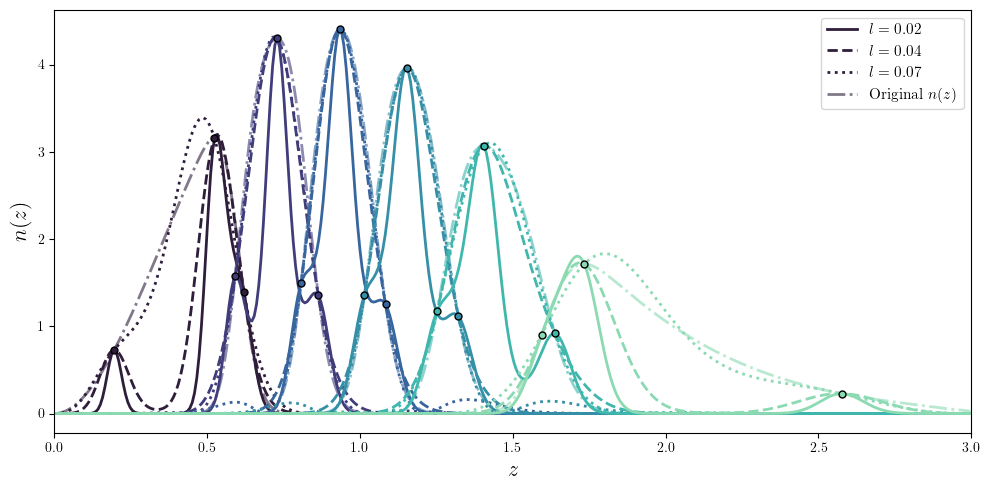

In [22]:
x_nodes_all_3, y_nodes_all_3 = compute_cdf_nodes(z_nz, dndz_she_norm, 3)
corr_lens = [0.02, 0.04, 0.07]
gp_predictions_corr = {}
for corr_len in corr_lens:
    gp_predictions_corr[corr_len] = reconstruct_all_bins(z_pred, x_nodes_all_3, y_nodes_all_3, z_bounds, corr_len=corr_len, amp=0.04, alpha=alpha, kernel_class=RBF, nu=1.5)

palette = sns.color_palette("mako", 6)
linestyles = {0.02: "-", 0.04: "--", 0.07: ":"}
fig, ax = plt.subplots(figsize=(10, 5))
for j in range(len(dndz_she_norm)):
    bin_id = j + 1
    for corr_len in corr_lens:
        if j == 0:
            ax.plot(z_pred, gp_predictions_corr[corr_len][bin_id], color=palette[j], ls=linestyles[corr_len], lw=2, label=fr"$l={corr_len:.2f}$")
        else:
            ax.plot(z_pred, gp_predictions_corr[corr_len][bin_id], color=palette[j], ls=linestyles[corr_len], lw=2)
    if j == 0:
        ax.plot(z_nz, dndz_she_norm[bin_id], color=palette[j], ls="-.", alpha=0.6, lw=2, label="Original $n(z)$")
    else:
        ax.plot(z_nz, dndz_she_norm[bin_id], color=palette[j], ls="-.", alpha=0.6, lw=2)
    ax.scatter(x_nodes_all_3[j], y_nodes_all_3[j], color=palette[j], s=25, edgecolor="black", zorder=3)
ax.set_xlabel(r"$z$", fontsize=16)
ax.set_ylabel(r"$n(z)$", fontsize=16)
ax.set_xlim(0, 3)
ax.legend(fontsize=11)
plt.tight_layout()

### Comparing Matern and RBF kernels

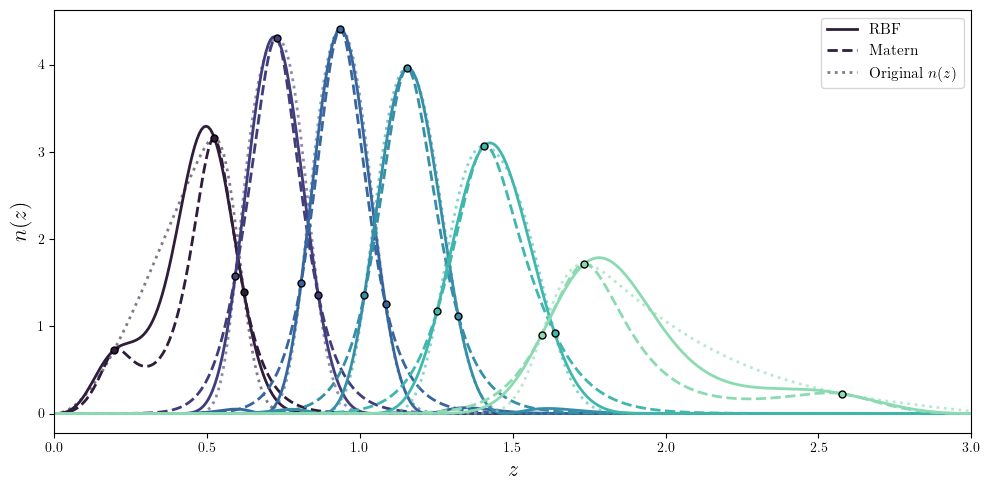

In [20]:
x_nodes_all_3, y_nodes_all_3 = compute_cdf_nodes(z_nz, dndz_she_norm, 3)
gp_predictions_rbf = reconstruct_all_bins(z_pred, x_nodes_all_3, y_nodes_all_3, z_bounds, corr_len=0.065, amp=0.04, alpha=alpha, kernel_class=RBF, nu=1.5)
gp_predictions_matern = reconstruct_all_bins(z_pred, x_nodes_all_3, y_nodes_all_3, z_bounds, corr_len=0.065, amp=0.04, alpha=alpha, kernel_class=Matern, nu=1.5)

fig, ax = plt.subplots(figsize=(10, 5))
for j in range(len(dndz_she_norm)):
    bin_id = j + 1
    if j == 0:
        ax.plot(z_pred, gp_predictions_rbf[bin_id], color=palette[j], lw=2, label="RBF")
        ax.plot(z_pred, gp_predictions_matern[bin_id], color=palette[j], ls="--", lw=2, label="Matern")
        ax.plot(z_nz, dndz_she_norm[bin_id], color=palette[j], ls=":", alpha=0.6, lw=2, label="Original $n(z)$")
    else:
        ax.plot(z_pred, gp_predictions_rbf[bin_id], color=palette[j], lw=2)
        ax.plot(z_pred, gp_predictions_matern[bin_id], color=palette[j], ls="--", lw=2)
        ax.plot(z_nz, dndz_she_norm[bin_id], color=palette[j], ls=":", alpha=0.6, lw=2)
    ax.scatter(x_nodes_all_3[j], y_nodes_all_3[j], color=palette[j], s=25, edgecolor="black", zorder=3)
ax.set_xlabel(r"$z$", fontsize=16)
ax.set_ylabel(r"$n(z)$", fontsize=16)
ax.set_xlim(0, 3)
ax.legend(fontsize=11)
plt.tight_layout()